# 02 - Suy luận và toán

**Đo cái gì?** GSM8K: bài toán đố cấp tiểu học, model phải tự viết lời giải nhiều bước rồi đưa ra đáp số.

**Vì sao cần?** Kiểm tra khả năng suy luận từng bước, khác với trắc nghiệm ở notebook 01. Liên quan đến việc model có suy ra đúng nguyên nhân từ nhiều số liệu cảm biến hay không.

**Cách đọc biểu đồ:** Điểm = % bài giải ra đúng đáp số. Model dưới 1 tỉ tham số thường rất thấp; điểm thấp ở đây là bình thường và là thông tin hữu ích cho báo cáo.

**Giới hạn (để chuẩn bị phản biện):** Chỉ lấy 100 bài; model phải tự viết nên chạy lâu hơn notebook 01. BBH (suy luận khó hơn) chưa đưa vào vì quá lâu; thêm `"bbh": 5` vào `LIMITS` nếu muốn.

In [1]:
import slm_tools as st
import numpy as np
import pandas as pd

In [2]:
LIMITS = {"gsm8k": 100}

def measure(cfg):
    return st.lm_eval_scores(cfg, LIMITS)

Chạy ô này sẽ lần lượt bật từng model, đo, rồi lưu vào thư mục `results/`. Nếu bị ngắt giữa chừng, chạy lại: model nào đã xong sẽ được bỏ qua.

In [3]:
base_cfgs = list({c["name"]: c for c in st.all_configs()}.values())   # 9 model gốc, không lặp
st.run_all("reasoning", measure, configs=base_cfgs, needs_server=False)

[đã có] SmolLM2-135M-Instruct (F16)
[đã có] Qwen2.5-0.5B-Instruct (F16)
[đã có] Qwen3-0.6B (F16)
[đã có] Gemma-3-1B-it (F16)
[đã có] Arch-Agent-1.5B (Q8)
[đã có] xLAM-2-1B-fc-r (Q8)
[đã có] Qwen3-1.7B (Q8)
[đã có] Arch-Agent-3B (Q4)
[đang chạy] Phi-4-mini-instruct (Q4)


c:\Users\Minor\Downloads\slm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
pretrained=pretrained=microsoft/Phi-4-mini-instruct,dtype=bfloat16,device=cuda:0 appears to be an instruct or chat variant but chat template
        is not applied. Recommend setting `apply_chat_template` (optionally `fewshot_as_multiturn`).
Running generate_until requests: 100%|██████████| 100/100 [36:30<00:00, 21.91s/it]   


   xong sau 2242s


## Biểu đồ - Model nào giải toán tốt nhất?

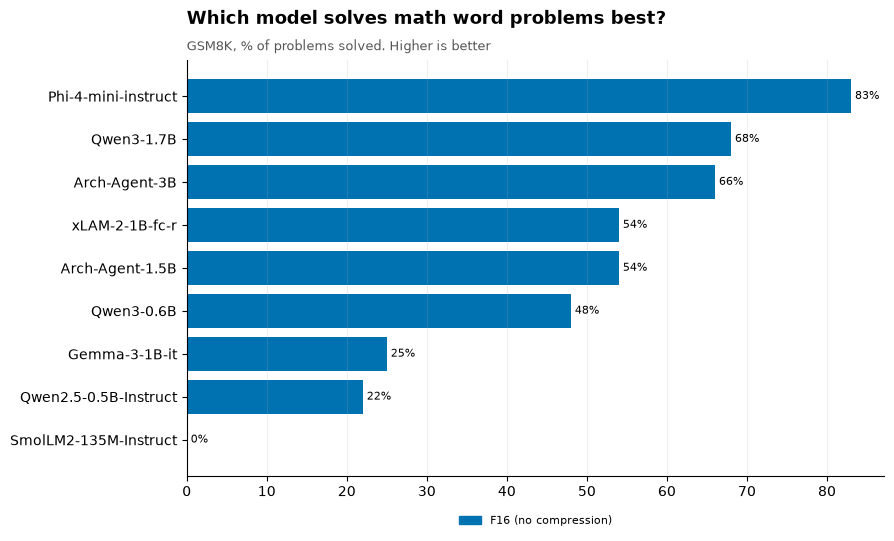

In [4]:
df = st.load_base("reasoning")
st.bar_chart(df, "gsm8k", "Which model solves math word problems best?", "GSM8K, % of problems solved. Higher is better", name="02_reasoning")